# 03 · Correlational stage, both arms (P1–P4)

Runs the pre-registered screen (`Docs/PREREGISTRATION.md`, sections 5 and 6) with one pipeline on every model. **FIT/VAL only.** DISCOVERY and SCREEN are v3's stays, loaded by ID, never re-drawn.

| Cell | What | Pre-registration |
|---|---|---|
| 5–6 | Screen on softmax × 5 seeds and sigmoid × 5 seeds (soup), control band, head rule, **seed rule**, reading of the result | 5.1–5.7 |
| 7 | Heads carried forward (top 6 per model) → `reports/03_heads.json`, read by notebook 04 | 5.8 |
| 8–9 | Total mass on the analysis queries; attention knockouts; **is the sigmoid arm alive?** → `reports/03_alive.json` | 6.1–6.4 |
| 10 | Heterogeneity with cluster-robust errors; S5 trigger and subgroup search | 5.9, 9 |
| 11–12 | Sensitivity families; best single epoch | 5.10 |
| 13–15 | **Exploratory:** kernel arms, reversed residualisation, trained-minus-init, PhysioNet set B | 12 |

Governance: every printed number is an aggregate. Per-stay coefficients stay in memory. Nothing from LOC, CONF or EXT is loaded.

Order: run `02` first (it trains every model this notebook reads). Set `SMOKE_TEST = True` once for a dry run; it needs the smoke models of `02`.

In [1]:
# ============================ CELL 1 · BOOTSTRAP: clone the repo, import sepsis_core from it ============================
REPO_URL = "https://github.com/Myakey/sepsis-transformer-analysis.git"
REPO_REF = "main"                                  # branch, tag or commit hash. PIN A COMMIT HASH for any run you will report.
REPO_DIR = "/content/sepsis-transformer-analysis"

import os, sys, subprocess
sys.dont_write_bytecode = True
if "google.colab" in sys.modules and not os.path.exists("/content/drive/MyDrive"):      # Drive holds the data and the checkpoints
    from google.colab import drive
    drive.mount("/content/drive")

def _git(*args, cwd=None):
    r = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True)
    if r.returncode != 0: raise RuntimeError(f"git {' '.join(args[:2])} failed: {r.stderr.strip()[-300:]}")
    return r.stdout.strip()

def _auth_url(url):
    tok = None                                     # private repo: Colab secret GITHUB_TOKEN (Notebook access on)
    try:
        from google.colab import userdata
        tok = userdata.get("GITHUB_TOKEN")
    except Exception:
        tok = os.environ.get("GITHUB_TOKEN")
    return url.replace("https://", f"https://{tok}@") if tok else url

if not os.path.isdir(os.path.join(REPO_DIR, ".git")): _git("clone", "--quiet", _auth_url(REPO_URL), REPO_DIR)
else: _git("fetch", "--quiet", "--all", cwd=REPO_DIR)
_git("checkout", "--quiet", REPO_REF, cwd=REPO_DIR)
if REPO_REF in _git("branch", "--format=%(refname:short)", cwd=REPO_DIR).split(): _git("pull", "--quiet", "--ff-only", cwd=REPO_DIR)
_git("remote", "set-url", "origin", REPO_URL, cwd=REPO_DIR)        # never leave a token in the clone's config
CORE_COMMIT = _git("rev-parse", "HEAD", cwd=REPO_DIR)
os.environ["SEPSIS_PROJECT_ROOT"] = REPO_DIR
os.environ["SEPSIS_CORE_COMMIT"] = CORE_COMMIT
for m in [k for k in sys.modules if k == "sepsis_core" or k.startswith("sepsis_core.")]: del sys.modules[m]
if os.path.join(REPO_DIR, "Notebooks", "v4") not in sys.path: sys.path.insert(0, os.path.join(REPO_DIR, "Notebooks", "v4"))

import importlib.util
_need = [p for p in ("mlflow", "lightgbm") if importlib.util.find_spec(p) is None]
if _need: subprocess.call([sys.executable, "-m", "pip", "install", "-q", *_need])

import json, time, gc
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import sepsis_core
from sepsis_core import config as C, data, dataset, models, engine, metrics, calibration, controls, runs, plots, tracking, attention, physionet, correlational, causal, explain
print("sepsis_core", sepsis_core.__version__, "@ commit", CORE_COMMIT[:12], f"({REPO_REF})", "| torch", torch.__version__)

Mounted at /content/drive
sepsis_core 4.2.0-phase3 @ commit 27d3c5272ea9 (main) | torch 2.14.1+cu130


In [2]:
# ============================ CELL 2 · SWITCHES ============================
SMOKE_TEST = True    # True = dry run on the smoke models of 02, with freshly drawn stays (v3's list does not apply to the smoke subsample)
STAGES = dict(screen=True, knockout=True, heterogeneity=True, sensitivity=True, single_epoch=True, kernel=True, exploratory=True, physionet_setB=True)
FORCE = False            # True = recompute screens even if their JSON is on Drive
STAGES["physionet_setB"] = False

runs.setup(smoke=SMOKE_TEST)
if not data.FoldGuard("correlational").prereg_frozen():
    raise PermissionError("Docs/PREREGISTRATION.md and Docs/PREREGISTRATION.frozen are not both in this commit. 03 does not run on real data before the freeze.")
SEEDS = list(C.CFG.SEEDS)[: (2 if SMOKE_TEST else 5)]; PRIMARY = SEEDS[0]
ARMS = ("softmax", "sigmoid"); KERNEL_SEEDS = SEEDS[: (1 if SMOKE_TEST else 3)]
HP = dict(C.V3_BEST_HP)
OUT = os.path.join(runs.run_root(), "reports", "03"); os.makedirs(OUT, exist_ok=True)
SUMMARY = dict(core_commit=CORE_COMMIT, run=C.CFG.RUN_NAME, seeds=SEEDS, smoke=SMOKE_TEST)

def have(name, which="best.pt"): return os.path.exists(os.path.join(runs.model_dir(name), which))
def need(name, which="best.pt"):
    if not have(name, which):
        raise FileNotFoundError(f"model '{name}' ({which}) is not in {runs.run_root()}/models. Run notebook 02 first" + (" with SMOKE_TEST = True" if SMOKE_TEST else "") + ".")
print("seeds:", SEEDS, "| primary:", PRIMARY, "| constants: SESOI", C.CFG.CORR_SESOI, "| band P%g" % C.CFG.CORR_BAND_Q, "| top-k", C.CFG.CORR_TOP_K, "| queries from position", C.CFG.CORR_MIN_T)

[mlflow] connected to DagsHub: https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow | experiment: sepsis-attention-v4
run=v4_last168_smoke | smoke=True | device=cuda amp=torch.float16 | core commit=27d3c5272ea9 | view=v3: most recent 168 h per stay | artifacts=/content/drive/MyDrive/sepsis_v4/v4_last168_smoke | mlflow=ON https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow
seeds: [42, 1042] | primary: 42 | constants: SESOI 0.05 | band P95 | top-k 6 | queries from position 8


In [3]:
# ============================ CELL 3 · DATA: FIT/VAL, severity (analysis only), v3's DISCOVERY / SCREEN stays ============================
B = runs.prepare_mimic(stage="correlational"); st = B["store"]
SEV_ALL, SUBJ = correlational.load_severity(st, B["val_idx"], [C.CFG.CORR_SEVERITY_COL] + list(correlational.ALT_SEVERITY))
SEV_KEY = list(SEV_ALL)[0]
if SEV_KEY.lower() != C.CFG.CORR_SEVERITY_COL.lower(): raise KeyError(f"the primary severity column {C.CFG.CORR_SEVERITY_COL} is not in the parquet")
SEV = SEV_ALL.pop(SEV_KEY)
if SMOKE_TEST: SPLITS, SPLIT_INFO = correlational.draw_splits(st, SEV, B["val_idx"], SUBJ)
else:          SPLITS, SPLIT_INFO = correlational.v3_splits(st)
SCREEN = correlational.Screen(st, SEV, SUBJ, SPLITS, B["pre"].feat, alt_sev=SEV_ALL)
SUMMARY["splits"] = SPLIT_INFO
print(f"analysis stays: DISCOVERY {len(SPLITS['DISCOVERY'])} | SCREEN {len(SPLITS['SCREEN'])} | source: {SPLIT_INFO['source']}")
print(f"severity: {SEV_KEY} | sensitivity definitions found: {list(SEV_ALL)} | stays longer than the {C.CFG.MAX_SEQ_LEN} h window: "
      f"{sum(SCREEN.truncated.values())} of {len(SCREEN.truncated)} | v3 band (clr) for reference: {SPLIT_INFO.get('v3_band_clr')}")

[full36] cohort: rows=3,966,669 stays=74,704 patients=56,075 pos_rate=1.1461% | split sha1=65441cff1a47 | septic stays=11,731 early-onset=65.3%
[full36] stays FIT=1,424 VAL=252 | rows=83,843 | features=36 | hour-gap violations=0 | FIT prevalence/horizon=[0.0102, 0.0095, 0.009] | focal alpha(prevalence)=0.9904 | data hash=6b35d36f8679f795 | store loaded from cache
analysis stays: DISCOVERY 40 | SCREEN 40 | source: drawn (v3 procedure)
severity: SOFA_total | sensitivity definitions found: ['SOFA_resp', 'SOFA_coag', 'SOFA_liver', 'SOFA_cv', 'SOFA_cns', 'SOFA_renal', 'SOFA_delta'] | stays longer than the 168 h window: 2 of 80 | v3 band (clr) for reference: None


In [4]:
# ============================ CELL 4 · THE SCREEN OF ONE MODEL (same code for every arm, seed, checkpoint and control) ============================
PLAN_TRAINED = {"DISCOVERY": ["real", "circ_shift", "donor", "rand_proj", "real@t24", "real~rev"] + [f"sev:{c}" for c in SEV_ALL], "SCREEN": ["real"]}
PLAN_CONTROL = {"DISCOVERY": ["real"], "SCREEN": ["real"]}
RUNS, REC = {}, {}        # RUNS: (model, checkpoint) -> per-stay fits, in memory only. REC: (arm, seed, checkpoint) -> the JSON record

def run_of(name, which, arm, plan, screen=None):
    key = (name, which, id(screen or SCREEN))
    if key not in RUNS:
        need(name, which); m = runs.load_trained(name, (screen or SCREEN).store, which); t0 = time.time()
        RUNS[key] = (screen or SCREEN).run(m, arm, plan); del m
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        print(f"    captured {name} ({which}) in {time.time() - t0:.0f}s")
    return RUNS[key]

def roles_of(arm, seed, which, prefix="", screen=None):
    name = f"{prefix}{arm}_s{seed}"
    roles = dict(trained=run_of(name, which, arm, PLAN_TRAINED, screen), init=run_of(name, "init.pt", arm, PLAN_CONTROL, screen))
    for role, nm in (("shuf_v3", f"{prefix}{arm}_shuf_v3"), ("shuf_budget", f"{prefix}{arm}_shuf_budget"), ("shuf_budget_noaux", f"{prefix}{arm}_shuf_budget_noaux")):
        if have(nm): roles[role] = run_of(nm, "best.pt", arm, PLAN_CONTROL, screen)
        elif role == "shuf_v3" and arm in ARMS: need(nm)
    return name, roles

def screen_model(arm, seed, which="best.pt", prefix=""):
    name = f"{prefix}{arm}_s{seed}"; path = os.path.join(OUT, f"{name}__{which.replace('.pt', '')}.json")
    if os.path.exists(path) and not FORCE: rec = json.load(open(path))
    else:
        name, roles = roles_of(arm, seed, which, prefix)
        rec = correlational.analyse(roles, arm); rec.update(model=name, checkpoint=which, seed=int(seed), core_commit=CORE_COMMIT)
        json.dump(rec, open(path, "w"), default=runs._js)
    REC[(prefix + arm, seed, which)] = rec; return rec

def line(rec, dv=None):
    d = rec["by_dv"][dv or rec["primary_dv"]]; c = d["counts"]
    return (f"{rec['model']:<22s} {rec['checkpoint']:<13s} DV {dv or rec['primary_dv']:<5s} band {d['band']:.4f} thr {d['threshold']:.4f} | max|b1| {d['max_abs_trained']:.3f} | heads pass+confirm: "
            f"trained {c['trained']} / untrained {c.get('init')} / shuffled {c.get('shuf_v3')} / budget {c.get('shuf_budget')} / aux-off {c.get('shuf_budget_noaux')} | "
            f"E {d['E']} | equivalent to 0 (TOST): {d['n_tost_equivalent']}/{rec['L'] * rec['H']}" + ("" if rec["band_complete"] else " | BAND INCOMPLETE (a control model is missing)"))

## Primary screen: softmax and sigmoid, five paired seeds, soup checkpoint

Head rule (v3, unchanged): a head passes on DISCOVERY iff |b1| > max(band, 0.05) and both CIs exclude 0; it is confirmed on SCREEN iff same sign, |b1| > 0.05, CI excludes 0. The band is the 95th percentile of |pooled b1| over all heads of five control sets: the model's own `init.pt`, the arm's v3-protocol shuffled-label model, and the trained model with circular-shift, donor and random-projection severity. The budget-matched and aux-off shuffled-label controls are shown beside it and never enter it.

In [5]:
# ============================ CELL 5 · PRIMARY SCREEN ============================
if STAGES["screen"]:
    for seed in SEEDS:
        for arm in ARMS:
            print(line(screen_model(arm, seed)))

/content/sepsis-transformer-analysis/Notebooks/v4/sepsis_core/correlational.py:160: RuntimeWarning: Mean of empty slice
  mu, sd = Xc.mean(0), Xc.std(0)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:208: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


    captured softmax_s42 (best.pt) in 2s
    captured softmax_s42 (init.pt) in 1s
    captured softmax_shuf_v3 (best.pt) in 1s
    captured softmax_shuf_budget (best.pt) in 1s
    captured softmax_shuf_budget_noaux (best.pt) in 1s
softmax_s42            best.pt       DV clr   band 0.2159 thr 0.2159 | max|b1| 0.310 | heads pass+confirm: trained 2 / untrained 1 / shuffled 3 / budget 2 / aux-off 3 | E -1 | equivalent to 0 (TOST): 0/16
    captured sigmoid_s42 (best.pt) in 2s
    captured sigmoid_s42 (init.pt) in 1s
    captured sigmoid_shuf_v3 (best.pt) in 1s
    captured sigmoid_shuf_budget (best.pt) in 1s
    captured sigmoid_shuf_budget_noaux (best.pt) in 1s
sigmoid_s42            best.pt       DV loga  band 0.1138 thr 0.1138 | max|b1| 0.185 | heads pass+confirm: trained 1 / untrained 1 / shuffled 3 / budget 2 / aux-off 2 | E -2 | equivalent to 0 (TOST): 4/16
    captured softmax_s1042 (best.pt) in 2s
    captured softmax_s1042 (init.pt) in 1s
softmax_s1042          best.pt       DV cl

In [6]:
# ============================ CELL 6 · SEED RULE (5.6) AND READING (5.7) ============================
def verdicts(which="best.pt", arms=ARMS, seeds=SEEDS, prefix=""):
    out = {}
    for arm in arms:
        recs = [REC[(prefix + arm, s, which)] for s in seeds if (prefix + arm, s, which) in REC]
        if not recs: continue
        out[arm] = {}
        for dv in ("primary", "clr", "normw"):
            key = recs[0]["primary_dv"] if dv == "primary" else dv
            E = [r["by_dv"][key]["E"] for r in recs]; En = [r["by_dv"][key]["E_noaux"] for r in recs]; Eb = [r["by_dv"][key]["E_budget"] for r in recs]
            out[arm][dv] = dict(dv=key, E=E, verdict=correlational.seed_verdict(E), E_aux_off=En, verdict_aux_off=correlational.seed_verdict(En),
                                E_budget_matched=Eb, verdict_budget_matched=correlational.seed_verdict(Eb))
    return out

V0 = verdicts(); SUMMARY["rung0_soup"] = V0
for arm, v in V0.items():
    p = v["primary"]
    print(f"{arm:<8s} primary DV ({p['dv']}): excess E per seed {p['E']} -> {p['verdict']}")
    print(f"         beside the band: aux-off control in E {p['E_aux_off']} -> {p['verdict_aux_off']} | budget-matched control in E {p['E_budget_matched']} -> {p['verdict_budget_matched']}")
    print(f"         cross-arm DV (row-centred logit): E {v['clr']['E']} -> {v['clr']['verdict']} | norm-weighted DV: E {v['normw']['E']} -> {v['normw']['verdict']}")
    if p["verdict"] == "ABSENT":
        print("         reading (A2): sepsis labels add nothing detectable beyond physiology learning."
              + (" The broader claim (nothing beyond architecture and inputs) also holds: ABSENT with the aux-off control." if p["verdict_aux_off"] == "ABSENT"
                 else " The broader claim is NOT made: the verdict with the aux-off control is " + p["verdict_aux_off"] + "."))
print("\nCorrelational analogue of the four-outcome table (the table itself is decided in 04, by intervention):")
print("   softmax:", V0.get("softmax", {}).get("primary", {}).get("verdict"), "| sigmoid:", V0.get("sigmoid", {}).get("primary", {}).get("verdict"))
print("Trained heads are expected to differ from zero; the null here is 'not distinguishable from controls', not 'no association'.")

softmax  primary DV (clr): excess E per seed [-1, 0] -> INCOMPLETE (2 of 5 seeds)
         beside the band: aux-off control in E [-1, 0] -> INCOMPLETE (2 of 5 seeds) | budget-matched control in E [0, 0] -> INCOMPLETE (2 of 5 seeds)
         cross-arm DV (row-centred logit): E [-1, 0] -> INCOMPLETE (2 of 5 seeds) | norm-weighted DV: E [0, 0] -> INCOMPLETE (2 of 5 seeds)
sigmoid  primary DV (loga): excess E per seed [-2, 0] -> INCOMPLETE (2 of 5 seeds)
         beside the band: aux-off control in E [-1, 0] -> INCOMPLETE (2 of 5 seeds) | budget-matched control in E [-1, 0] -> INCOMPLETE (2 of 5 seeds)
         cross-arm DV (row-centred logit): E [-1, -1] -> INCOMPLETE (2 of 5 seeds) | norm-weighted DV: E [1, 0] -> INCOMPLETE (2 of 5 seeds)

Correlational analogue of the four-outcome table (the table itself is decided in 04, by intervention):
   softmax: INCOMPLETE (2 of 5 seeds) | sigmoid: INCOMPLETE (2 of 5 seeds)
Trained heads are expected to differ from zero; the null here is 'not dist

In [7]:
# ============================ CELL 7 · HEADS CARRIED FORWARD (5.8): top 6 by |b1| on DISCOVERY, per model ============================
def heads_file():
    H = {}
    for (arm, seed, which), rec in REC.items():
        d = rec["by_dv"][rec["primary_dv"]]
        H.setdefault(rec["model"], {})[which] = dict(arm=rec["arm"], seed=seed, dv=rec["primary_dv"], threshold=d["threshold"], L=rec["L"], H=rec["H"], top=d["top"],
                                                     top_cross_arm_dv=rec["by_dv"]["clr"]["top"], E=d["E"])
    return H
for (arm, seed, which), rec in sorted(REC.items(), key=lambda kv: (kv[0][0], kv[0][1])):
    if which != "best.pt" or arm not in ARMS: continue
    top = rec["by_dv"][rec["primary_dv"]]["top"]
    print(f"{rec['model']:<16s} " + "  ".join(f"L{t['layer']}H{t['head']} {t['b1_disc']:+.3f}{'' if t['passed'] and t['confirmed'] else '*'}{'(layer 1)' if t['layer1'] else ''}" for t in top))
print("* = carried forward without passing the screen. Layer-1 heads cannot show effects on other hours.")
runs.save_json(heads_file(), "03_heads.json")

sigmoid_s42      L2H6 +0.185  L1H7 +0.113*(layer 1)  L1H1 +0.090*(layer 1)  L1H6 -0.090*(layer 1)  L2H5 +0.082*  L1H3 -0.081*(layer 1)
sigmoid_s1042    L1H7 -0.157(layer 1)  L2H2 +0.128  L2H4 +0.105*  L2H7 +0.102*  L1H1 +0.090*(layer 1)  L2H3 -0.080*
softmax_s42      L2H6 +0.310  L1H7 +0.232(layer 1)  L2H8 +0.213*  L1H1 +0.210*(layer 1)  L1H3 -0.187*(layer 1)  L1H5 -0.126*(layer 1)
softmax_s1042    L2H4 +0.275  L1H7 -0.268(layer 1)  L1H1 +0.220*(layer 1)  L2H2 +0.219*  L2H1 -0.218*  L1H2 +0.211*(layer 1)
* = carried forward without passing the screen. Layer-1 heads cannot show effects on other hours.
saved: /content/drive/MyDrive/sepsis_v4/v4_last168_smoke/reports/03_heads.json


'/content/drive/MyDrive/sepsis_v4/v4_last168_smoke/reports/03_heads.json'

## Total mass, and whether the sigmoid arm is alive (section 6)

Mass is measured here on the analysis stays, per layer, on queries at position ≥ 8. The value printed during training (0.24–0.26) came from the 256 shortest VAL stays and is not used.

softmax_s42     mean total mass per layer, analysis queries: [1.0, 1.0] | heads with > 5% of softmax weights below 1e-6: 0
sigmoid_s42     mean total mass per layer, analysis queries: [1.108, 1.026] | heads with > 5% of softmax weights below 1e-6: 0 | mass vs mean severity of the window: equivalent to 0 in 0% of heads (layers >= 2)
softmax_s1042   mean total mass per layer, analysis queries: [1.0, 1.0] | heads with > 5% of softmax weights below 1e-6: 0
sigmoid_s1042   mean total mass per layer, analysis queries: [1.029, 1.054] | heads with > 5% of softmax weights below 1e-6: 0 | mass vs mean severity of the window: equivalent to 0 in 0% of heads (layers >= 2)

sigmoid, step 0 (init.pt): mean total mass by query position vs the arithmetic T/(T+1):
   position   8: layers [0.882, 0.921] | T/(T+1) = 0.900
   position  12: layers [0.954, 0.907] | T/(T+1) = 0.929
   position  24: layers [1.169, 1.014] | T/(T+1) = 0.962
   position  48: layers [1.077, 1.111] | T/(T+1) = 0.980
   position  96

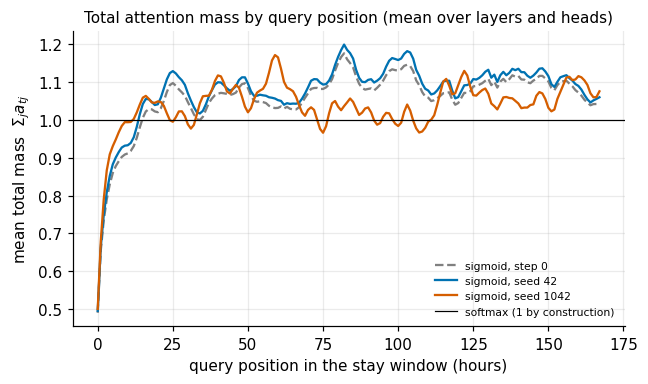


6.4 total mass insensitive to the severity composition of the window (every head in layers >= 2 equivalent to 0, 5 of 5 seeds): INCOMPLETE (2 of 5 seeds)


In [8]:
# ============================ CELL 8 · TOTAL MASS (6.1) AND ITS DEPENDENCE ON THE WINDOW (6.4) ============================
MASS = {}
for seed in SEEDS:
    for arm in ARMS:
        if (arm, seed, "best.pt") not in REC: continue
        m = REC[(arm, seed, "best.pt")]["mass"]; MASS[f"{arm}_s{seed}"] = m
        comp = m.get("composition")
        print(f"{arm}_s{seed:<6d} mean total mass per layer, analysis queries: {[round(x, 3) for x in m['by_layer']]} | heads with > 5% of softmax weights below 1e-6: {m['floor_heads_above_5pct']}"
              + (f" | mass vs mean severity of the window: equivalent to 0 in {comp['share_equivalent_layers_ge2']:.0%} of heads (layers >= 2)" if comp else ""))
POS = [p for p in (8, 12, 24, 48, 96, 167) if p < C.CFG.MAX_SEQ_LEN]
key0 = (f"sigmoid_s{PRIMARY}", "init.pt", id(SCREEN))
if key0 in RUNS:
    bp = RUNS[key0]["mass"]["by_pos"]                                        # (L, T) at step 0
    print("\nsigmoid, step 0 (init.pt): mean total mass by query position vs the arithmetic T/(T+1):")
    for p in POS: print(f"   position {p:>3d}: layers {[round(float(x), 3) for x in bp[:, p]]} | T/(T+1) = {(p + 1) / (p + 2):.3f}")
    plots.style(); fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.plot(np.nanmean(bp, 0), color="grey", ls="--", label="sigmoid, step 0")
    for i, seed in enumerate(SEEDS):
        k = (f"sigmoid_s{seed}", "best.pt", id(SCREEN))
        if k in RUNS: ax.plot(np.nanmean(RUNS[k]["mass"]["by_pos"], 0), color=plots.OKABE_ITO[i % 8], label=f"sigmoid, seed {seed}")
    ax.axhline(1.0, color="k", lw=0.8, label="softmax (1 by construction)"); ax.set_xlabel("query position in the stay window (hours)"); ax.set_ylabel("mean total mass  $\\Sigma_j a_{tj}$")
    ax.set_title("Total attention mass by query position (mean over layers and heads)"); ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(runs.figure_path("03_mass_by_position.png"), bbox_inches="tight"); plt.show()
comp_flags = [REC[("sigmoid", s, "best.pt")]["mass"].get("composition", {}).get("all_heads_equivalent_layers_ge2") for s in SEEDS if ("sigmoid", s, "best.pt") in REC]
SUMMARY["mass"] = MASS; SUMMARY["mass_insensitive_to_composition"] = correlational.all_seeds(comp_flags)
print("\n6.4 total mass insensitive to the severity composition of the window (every head in layers >= 2 equivalent to 0, 5 of 5 seeds):", SUMMARY["mass_insensitive_to_composition"])

In [9]:
# ============================ CELL 9 · KNOCKOUTS AND THE STUDY OUTCOME OF 6.2 ============================
ALIVE = dict(per_seed={}, knockouts={})
if STAGES["knockout"]:
    def knock(name, which="best.pt"):
        p = os.path.join(OUT, f"knockout__{name}__{which.replace('.pt', '')}.json")
        if os.path.exists(p) and not FORCE: return json.load(open(p))
        need(name, which); k = correlational.knockout_report(B, name, which, n_boot=runs.STATE["n_boot"]); json.dump(k, open(p, "w"), default=runs._js); return k
    for seed in SEEDS:
        ks = {arm: knock(f"{arm}_s{seed}") for arm in ARMS}; ALIVE["knockouts"][seed] = ks
        for arm in ARMS:
            z, u = ks[arm]["zero"], ks[arm]["uniform"]
            print(f"{arm}_s{seed:<6d} AUROC intact {ks[arm]['auroc_intact']:.4f} | attention zeroed: drop {z['drop']:+.4f} [{z['lo']:+.4f}, {z['hi']:+.4f}] -> "
                  f"{'MATTERS' if correlational.knockout_matters(ks[arm]) else 'costs little'} | uniform rows (descriptive): drop {u['drop']:+.4f} [{u['lo']:+.4f}, {u['hi']:+.4f}]")
        mass = REC[("sigmoid", seed, "best.pt")]["mass"]["by_layer"] if ("sigmoid", seed, "best.pt") in REC else [float("nan")]
        done = os.path.join(runs.model_dir(f"sigmoid_s{seed}"), "done.json"); mpe = json.load(open(done)).get("mass_per_epoch") if os.path.exists(done) else None
        ALIVE["per_seed"][seed] = dict(outcome=correlational.seed_outcome(ks["sigmoid"], ks["softmax"], mass), sigmoid_mass_by_layer=mass, mass_floor=C.CFG.MASS_FLOOR,
                                       drift_flag=correlational.drift_flag(mass, mpe))
        print(f"   seed {seed}: {ALIVE['per_seed'][seed]['outcome']} | sigmoid mass by layer {[round(x, 3) for x in mass]} | drift flag {ALIVE['per_seed'][seed]['drift_flag']}")
    ALIVE["study_outcome"] = correlational.study_outcome([v["outcome"] for v in ALIVE["per_seed"].values()])
    print("\nSTUDY OUTCOME (6.2):", ALIVE["study_outcome"])
    print({"sigmoid ALIVE": "The four-outcome table is read as written in section 8.",
           "ATTENTION CONTRIBUTES LITTLE IN EITHER ARM": "Pre-specified outcome of the S1 type. No cell of the four-outcome table is claimed; verdicts on logits are shown and labelled "
                                                        "'pattern in logits that the prediction does not depend on'.",
           "sigmoid NOT ALIVE": "The sigmoid arm cannot serve as a null. No cell is claimed; the softmax verdict is reported alone."}.get(ALIVE["study_outcome"], "Fewer than 5 seeds: no study outcome yet."))
    runs.save_json(ALIVE, "03_alive.json"); SUMMARY["alive"] = ALIVE

softmax_s42     AUROC intact 0.4653 | attention zeroed: drop +0.0034 [-0.0124, +0.0288] -> costs little | uniform rows (descriptive): drop -0.0004 [-0.0020, +0.0017]
sigmoid_s42     AUROC intact 0.4628 | attention zeroed: drop +0.0027 [-0.0300, +0.0360] -> costs little | uniform rows (descriptive): drop -0.0009 [-0.0022, +0.0008]
   seed 42: attention contributes little in either arm | sigmoid mass by layer [1.108, 1.026] | drift flag False
softmax_s1042   AUROC intact 0.4900 | attention zeroed: drop -0.0109 [-0.0720, +0.0264] -> costs little | uniform rows (descriptive): drop -0.0000 [-0.0048, +0.0036]
sigmoid_s1042   AUROC intact 0.4853 | attention zeroed: drop -0.0160 [-0.0566, +0.0152] -> costs little | uniform rows (descriptive): drop -0.0004 [-0.0059, +0.0032]
   seed 1042: attention contributes little in either arm | sigmoid mass by layer [1.029, 1.054] | drift flag False

STUDY OUTCOME (6.2): INCOMPLETE (2 of 5 seeds)
Fewer than 5 seeds: no study outcome yet.
saved: /content/dr

In [10]:
# ============================ CELL 10 · HETEROGENEITY (5.9, cluster-robust) AND THE S5 TRIGGER ============================
if STAGES["heterogeneity"] and ("softmax", PRIMARY, "best.pt") in REC:
    HET = {}
    for arm in ARMS:
        h = REC[(arm, PRIMARY, "best.pt")]["by_dv"][REC[(arm, PRIMARY, "best.pt")]["primary_dv"]]["heads"]
        I2 = np.array([np.nan if x is None else x for x in h["I2_robust"]], float); lo = np.array([np.nan if x is None else x for x in h["pi_lo"]], float); hi = np.array([np.nan if x is None else x for x in h["pi_hi"]], float)
        pi0 = (lo < 0) & (hi > 0) & np.array(h["ci_excludes_0_robust"], bool)
        HET[arm] = dict(median_I2_robust=float(np.nanmedian(I2)), share_heads_I2_ge_075=float(np.nanmean(I2 >= C.CFG.S5_I2)), share_heads_PI_includes_0_while_CI_excludes_0=float(pi0.mean()),
                        median_I2_v3_estimator=float(np.nanmedian([x for x in h["I2_v3"] if x is not None])))
        print(f"{arm}_s{PRIMARY}: I2 median {HET[arm]['median_I2_robust']:.3f} with cluster-robust errors (v3 estimator: {HET[arm]['median_I2_v3_estimator']:.3f}) | heads with I2 >= {C.CFG.S5_I2}: "
              f"{HET[arm]['share_heads_I2_ge_075']:.0%} | heads whose 95% prediction interval includes 0 while the pooled CI excludes it: {HET[arm]['share_heads_PI_includes_0_while_CI_excludes_0']:.0%}")
    s5 = HET["softmax"]["share_heads_I2_ge_075"] >= 0.5 or HET["softmax"]["share_heads_PI_includes_0_while_CI_excludes_0"] >= 0.5
    HET["S5_trigger"] = bool(s5); print("S5 trigger (softmax, primary seed):", "FIRES" if s5 else "does not fire")
    if s5:
        idx = np.concatenate([SPLITS["DISCOVERY"], SPLITS["SCREEN"]]); dens = np.array([st.M[SCREEN.info[nm][int(i)]["a"]: SCREEN.info[nm][int(i)]["a"] + SCREEN.info[nm][int(i)]["n"]].mean() for nm in SPLITS for i in SPLITS[nm]])
        msev = np.array([SCREEN.info[nm][int(i)]["var"]["real"].mean() for nm in SPLITS for i in SPLITS[nm]])
        def tert(v): lo_, hi_ = np.quantile(v, [1 / 3, 2 / 3]); return {int(i): (1.0 if x >= hi_ else 0.0 if x <= lo_ else np.nan) for i, x in zip(idx, v)}
        attrs = {"septic stay vs not": {int(i): float(st.stay_has_pos[i]) for i in idx}, "Unit1 vs not": {int(i): float(st.S[st.starts[i], 2] > 0.5) for i in idx},
                 "density: top vs bottom tertile": tert(dens), "mean severity: top vs bottom tertile": tert(msev)}
        name, roles = roles_of("softmax", PRIMARY, "best.pt")
        HET["subgroups"] = correlational.subgroup_search(roles["trained"], "softmax", attrs)
        print("EXPLORATORY subgroup search (Benjamini-Hochberg q = %.2f across heads x subgroups on DISCOVERY, confirmed on SCREEN):" % C.CFG.S5_FDR_Q)
        for r in HET["subgroups"]: print(f"   {r['subgroup']:<38s} n {r['n_disc']} | heads significant on DISCOVERY {r['heads_fdr_discovery']} | confirmed on SCREEN {r['heads_confirmed_screen']}")
    SUMMARY["heterogeneity"] = HET

softmax_s42: I2 median 0.894 with cluster-robust errors (v3 estimator: 0.983) | heads with I2 >= 0.75: 100% | heads whose 95% prediction interval includes 0 while the pooled CI excludes it: 81%
sigmoid_s42: I2 median 0.905 with cluster-robust errors (v3 estimator: 0.975) | heads with I2 >= 0.75: 100% | heads whose 95% prediction interval includes 0 while the pooled CI excludes it: 56%
S5 trigger (softmax, primary seed): FIRES
EXPLORATORY subgroup search (Benjamini-Hochberg q = 0.10 across heads x subgroups on DISCOVERY, confirmed on SCREEN):
   septic stay vs not                     n (3, 37) | heads significant on DISCOVERY 0 | confirmed on SCREEN 0
   Unit1 vs not                           n (8, 32) | heads significant on DISCOVERY 0 | confirmed on SCREEN 0
   density: top vs bottom tertile         n (12, 16) | heads significant on DISCOVERY 0 | confirmed on SCREEN 0
   mean severity: top vs bottom tertile   n (13, 16) | heads significant on DISCOVERY 0 | confirmed on SCREEN 0


In [11]:
# ============================ CELL 11 · PRE-SPECIFIED SENSITIVITY ANALYSES (5.10), primary seed, both arms ============================
if STAGES["sensitivity"]:
    SENS = {}
    for arm in ARMS:
        if (arm, PRIMARY, "best.pt") not in REC: continue
        name, roles = roles_of(arm, PRIMARY, "best.pt"); thr = REC[(arm, PRIMARY, "best.pt")]["by_dv"][correlational.PRIMARY_DV[arm]]["threshold"]
        rows, pv = correlational.sensitivity(roles["trained"], arm, threshold=thr); SENS[arm] = dict(rows=rows)
        print(f"\n{name}: primary threshold {thr:.4f}. None of these changes the primary verdict; they are reported beside it.")
        for r in rows: print(f"   {r['analysis']:<42s} max|b1| {r['max_abs_b1']:.3f} | heads beyond the primary threshold {r['heads_beyond_primary_threshold']} | correlation with the primary b1 across heads {r['correlation_with_primary']:+.3f}")
        if pv:
            names = list(pv); rej = correlational.bh_fdr(np.array([pv[n] for n in names]), C.CFG.FDR_Q)
            SENS[arm]["fdr"] = {n: int(rej[i].sum()) for i, n in enumerate(names)}
            print(f"   severity-definition family, Benjamini-Hochberg q = {C.CFG.FDR_Q} across heads x definitions: heads with b1 != 0: {SENS[arm]['fdr']}")
    SUMMARY["sensitivity"] = SENS

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/content/sepsis-transformer-analysis/Notebooks/v4/sepsis_core/correlational.py:405: RuntimeWarning: All-NaN slice encountered
  rows.append(dict(analysis=name, max_abs_b1=float(np.nanmax(np.abs(m["est"]))), heads_beyond_primary_threshold=(int((np.abs(m["est"]) > threshold).sum()) if threshold else None),



softmax_s42: primary threshold 0.2159. None of these changes the primary verdict; they are reported beside it.
   queries at position >= 24 only             max|b1| 0.271 | heads beyond the primary threshold 2 | correlation with the primary b1 across heads +0.925
   EXPLORATORY reversed residualisation       max|b1| 0.238 | heads beyond the primary threshold 1 | correlation with the primary b1 across heads +0.986
   severity = SOFA_cns                        max|b1| 0.277 | heads beyond the primary threshold 1 | correlation with the primary b1 across heads +0.919
   severity = SOFA_coag                       max|b1| 0.236 | heads beyond the primary threshold 2 | correlation with the primary b1 across heads +0.811
   severity = SOFA_cv                         max|b1| 0.262 | heads beyond the primary threshold 2 | correlation with the primary b1 across heads +0.984
   severity = SOFA_delta                      max|b1| 0.268 | heads beyond the primary threshold 2 | correlation with the p

In [12]:
# ============================ CELL 12 · SENSITIVITY: BEST SINGLE EPOCH INSTEAD OF THE SOUP (all seeds, both arms) ============================
if STAGES["single_epoch"]:
    for seed in SEEDS:
        for arm in ARMS:
            if have(f"{arm}_s{seed}", "best_epoch.pt"): print(line(screen_model(arm, seed, "best_epoch.pt")))
    V1 = verdicts("best_epoch.pt"); SUMMARY["rung0_single_epoch"] = V1
    for arm, v in V1.items(): print(f"{arm:<8s} best single epoch: E per seed {v['primary']['E']} -> {v['primary']['verdict']}   (soup: {V0.get(arm, {}).get('primary', {}).get('verdict')})")
    runs.save_json(heads_file(), "03_heads.json")

/content/sepsis-transformer-analysis/Notebooks/v4/sepsis_core/correlational.py:160: RuntimeWarning: Mean of empty slice
  mu, sd = Xc.mean(0), Xc.std(0)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:208: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


    captured softmax_s42 (best_epoch.pt) in 3s
softmax_s42            best_epoch.pt DV clr   band 0.2159 thr 0.2159 | max|b1| 0.310 | heads pass+confirm: trained 2 / untrained 1 / shuffled 3 / budget 2 / aux-off 3 | E -1 | equivalent to 0 (TOST): 0/16
    captured sigmoid_s42 (best_epoch.pt) in 2s
sigmoid_s42            best_epoch.pt DV loga  band 0.1138 thr 0.1138 | max|b1| 0.185 | heads pass+confirm: trained 1 / untrained 1 / shuffled 3 / budget 2 / aux-off 2 | E -2 | equivalent to 0 (TOST): 4/16
    captured softmax_s1042 (best_epoch.pt) in 2s
softmax_s1042          best_epoch.pt DV clr   band 0.2550 thr 0.2550 | max|b1| 0.275 | heads pass+confirm: trained 2 / untrained 2 / shuffled 2 / budget 1 / aux-off 1 | E 0 | equivalent to 0 (TOST): 0/16
    captured sigmoid_s1042 (best_epoch.pt) in 2s
sigmoid_s1042          best_epoch.pt DV loga  band 0.1148 thr 0.1148 | max|b1| 0.157 | heads pass+confirm: trained 2 / untrained 2 / shuffled 2 / budget 1 / aux-off 1 | E 0 | equivalent to 0 (TO

## Exploratory analyses (pre-registration, section 12)

Everything below is labelled exploratory wherever it is shown. None of it enters a confirmatory decision.

In [13]:
# ============================ CELL 13 · EXPLORATORY: kernel attention inside the same trunk ============================
if STAGES["kernel"]:
    for seed in KERNEL_SEEDS:
        if have(f"kernel_s{seed}"): print(line(screen_model("kernel", seed)))
    if have(f"kernel_raw_s{PRIMARY}"):
        r = screen_model("kernel_raw", PRIMARY); print(line(r)); print("   kernel_raw has no shuffled-label control: its band holds the untrained network and the surrogate severities only.")
        print(f"   kernel_raw total mass per layer on analysis queries: {[round(x, 4) for x in r['mass']['by_layer']]} (the training probe value 0.039 came from the shortest stays)")
        if STAGES["knockout"]:
            k = knock(f"kernel_raw_s{PRIMARY}"); z = k["zero"]
            print(f"   kernel_raw attention zeroed: AUROC {k['auroc_intact']:.4f} -> drop {z['drop']:+.4f} [{z['lo']:+.4f}, {z['hi']:+.4f}] ({'matters' if correlational.knockout_matters(k) else 'costs little'})")
            SUMMARY["kernel_raw_knockout"] = k
    VK = verdicts(arms=("kernel",), seeds=KERNEL_SEEDS); SUMMARY["exploratory_kernel"] = VK
    if "kernel" in VK: print(f"kernel (EXPLORATORY, {len(KERNEL_SEEDS)} seeds, so the 5-seed rule cannot be applied): E per seed {VK['kernel']['primary']['E']}")

    captured kernel_s42 (best.pt) in 3s
    captured kernel_s42 (init.pt) in 1s
    captured kernel_shuf_v3 (best.pt) in 1s
kernel_s42             best.pt       DV clr   band 0.2670 thr 0.2670 | max|b1| 0.337 | heads pass+confirm: trained 2 / untrained 3 / shuffled 1 / budget None / aux-off None | E -1 | equivalent to 0 (TOST): 0/16
    captured kernel_raw_s42 (best.pt) in 2s
    captured kernel_raw_s42 (init.pt) in 1s
kernel_raw_s42         best.pt       DV loga  band 0.2739 thr 0.2739 | max|b1| 0.458 | heads pass+confirm: trained 3 / untrained 4 / shuffled None / budget None / aux-off None | E None | equivalent to 0 (TOST): 0/16 | BAND INCOMPLETE (a control model is missing)
   kernel_raw has no shuffled-label control: its band holds the untrained network and the surrogate severities only.
   kernel_raw total mass per layer on analysis queries: [19.1756, 18.5614] (the training probe value 0.039 came from the shortest stays)
   kernel_raw attention zeroed: AUROC 0.5029 -> drop +0.0479

In [14]:
# ============================ CELL 14 · EXPLORATORY: reversed residualisation; trained minus untrained, head by head ============================
if STAGES["exploratory"]:
    EXPL = {}
    for arm in ARMS:
        if (arm, PRIMARY, "best.pt") not in REC: continue
        name, roles = roles_of(arm, PRIMARY, "best.pt"); tr, ini = roles["trained"], roles["init"]; K = tr["K"]; di = tr["dvs"].index(correlational.PRIMARY_DV[arm]); cols = slice(di * K, (di + 1) * K)
        ft, fi = tr["fits"][("DISCOVERY", "real")], ini["fits"][("DISCOVERY", "real")]
        common, it_, ii_ = np.intersect1d(ft["stays"], fi["stays"], return_indices=True)
        mean, lo, hi = causal.boot_mean(ft["b1"][it_][:, cols] - fi["b1"][ii_][:, cols], ft["groups"][it_])       # same network at step 0, so heads are aligned
        EXPL[arm] = dict(heads_ci_excludes_0=int(((lo > 0) | (hi < 0)).sum()), max_abs_difference=float(np.nanmax(np.abs(mean))), mean_abs_difference=float(np.nanmean(np.abs(mean))))
        print(f"{name}: trained minus untrained b1, per head, paired by stay: |difference| mean {EXPL[arm]['mean_abs_difference']:.3f}, max {EXPL[arm]['max_abs_difference']:.3f}; "
              f"CI excludes 0 in {EXPL[arm]['heads_ci_excludes_0']} of {K} heads (EXPLORATORY)")
    SUMMARY["exploratory_trained_minus_init"] = EXPL
    print("Reversed residualisation (severity residualised on deviation) is the row 'EXPLORATORY reversed residualisation' in Cell 11.")

softmax_s42: trained minus untrained b1, per head, paired by stay: |difference| mean 0.041, max 0.124; CI excludes 0 in 12 of 16 heads (EXPLORATORY)
sigmoid_s42: trained minus untrained b1, per head, paired by stay: |difference| mean 0.014, max 0.045; CI excludes 0 in 10 of 16 heads (EXPLORATORY)
Reversed residualisation (severity residualised on deviation) is the row 'EXPLORATORY reversed residualisation' in Cell 11.


In [15]:
# ============================ CELL 15 · EXPLORATORY: does the screen replicate on PhysioNet set B (Emory)? ============================
# Partial-SOFA proxy (MAP, platelets, bilirubin, creatinine) built with the same code on both cohorts; reduced-feature models; compared with the SAME proxy
# on MIMIC, never with full SOFA. Matched stratum primary, all stays beside it (A13). One seed, so the wording is "consistent with", never "confirmed".
if STAGES["physionet_setB"]:
    FEATS = physionet.reduced_features(); R = runs.prepare_mimic(features=FEATS, tag="r33", stage="correlational")
    for arm in ARMS: need(f"r33_{arm}_s{PRIMARY}")                              # trained by notebook 01b
    ST_SHUF, _rng = controls.shuffled_store(R["store"], R["fit_idx"]); SFIT = controls.v3_fit_subset(_rng, R["fit_idx"], 0.3)
    for arm in ARMS:                                                            # the band needs a shuffled-label control for the reduced-feature models: v3 protocol, FIT only
        runs.train_model(R, f"r33_{arm}_shuf_v3", {**HP, "arm": arm, "use_iculos": False}, seed=C.CFG.SEED + 5, role="control_shuffled_v3protocol", store=ST_SHUF, fit_idx=SFIT,
                         max_epochs=(1 if SMOKE_TEST else 4), patience=5, soup_k=0)
    del ST_SHUF; gc.collect()
    PROXY_M = correlational.partial_sofa(R["store"], R["pre"])
    base_m = SPLITS if SMOKE_TEST else correlational.v3_splits(R["store"])[0]
    SPL_M = {nm: np.array([int(i) for i in base_m[nm] if correlational.eligible(R["store"], PROXY_M, int(i))], np.int64) for nm in base_m}
    SCR = {"MIMIC VAL (v3 stays where the proxy varies)": correlational.Screen(R["store"], PROXY_M, SUBJ, SPL_M, FEATS)}
    dirs = physionet.extract(); RAWB = physionet.read_set(dirs["B"], "B", limit=(400 if SMOKE_TEST else None))
    PHB, _, PSTAT, meta = physionet.to_layout(RAWB, "B", features=FEATS); ONSET_B = data.stay_onset(PHB); CENS_B = meta.index[meta["censored"]].to_numpy(); del RAWB
    STB = R["pre"].transform(PHB); del PHB; MASK_B, minfo = physionet.matched_mask(STB, ONSET_B, CENS_B); PROXY_B = correlational.partial_sofa(STB, R["pre"])
    SUBJ_B = {int(s): int(s) for s in STB.ids[STB.starts]}
    for label, pool in (("set B, matched stratum (primary)", np.flatnonzero(MASK_B[STB.starts])), ("set B, all stays", np.arange(len(STB.starts)))):
        spl, info = correlational.draw_splits(STB, PROXY_B, pool, SUBJ_B); SCR[label] = correlational.Screen(STB, PROXY_B, SUBJ_B, spl, FEATS)
        print(f"{label}: eligible stays {info['n_eligible']:,} -> DISCOVERY {info['n_disc']} | SCREEN {info['n_screen']}")
    PLAN_X = {"DISCOVERY": ["real", "circ_shift", "donor", "rand_proj"], "SCREEN": ["real"]}; XB = {}
    for label, scr in SCR.items():
        for arm in ARMS:
            nm = f"r33_{arm}_s{PRIMARY}"
            roles = dict(trained=run_of(nm, "best.pt", arm, PLAN_X, scr), init=run_of(nm, "init.pt", arm, PLAN_CONTROL, scr), shuf_v3=run_of(f"r33_{arm}_shuf_v3", "best.pt", arm, PLAN_CONTROL, scr))
            rec = correlational.analyse(roles, arm); rec.update(model=nm, checkpoint="best.pt", cohort=label); XB.setdefault(label, {})[arm] = rec
            print(f"[{label}] " + line(rec))
    SUMMARY["exploratory_physionet_setB"] = {lab: {arm: dict(E=r["by_dv"][r["primary_dv"]]["E"], band=r["by_dv"][r["primary_dv"]]["band"], max_abs=r["by_dv"][r["primary_dv"]]["max_abs_trained"],
                                                               counts=r["by_dv"][r["primary_dv"]]["counts"]) for arm, r in d.items()} for lab, d in XB.items()}
    print("\nS5b (attention part): the set-B result is 'consistent with' MIMIC iff the sign of E (trained heads beyond the band minus the control networks) agrees, per arm. EXPLORATORY, one seed.")

In [16]:
# ============================ CELL 16 · SAVE (this is what to send back) ============================
SUMMARY["records"] = {f"{k[0]}_s{k[1]}__{k[2]}": {dv: {x: d[x] for x in ("band", "threshold", "counts", "E", "E_budget", "E_noaux", "n_tost_equivalent", "max_abs_trained", "band_members")}
                                                    for dv, d in r["by_dv"].items()} for k, r in REC.items()}
runs.save_json(SUMMARY, "03_summary.json")
runs.save_json(heads_file(), "03_heads.json")
print("\nNotebook 04 reads: reports/03_heads.json (heads carried forward) and reports/03_alive.json (study outcome of 6.2).")

saved: /content/drive/MyDrive/sepsis_v4/v4_last168_smoke/reports/03_summary.json
saved: /content/drive/MyDrive/sepsis_v4/v4_last168_smoke/reports/03_heads.json

Notebook 04 reads: reports/03_heads.json (heads carried forward) and reports/03_alive.json (study outcome of 6.2).


## What to send back

The printed output of Cells 5, 6, 8, 9, 10, 11 and 12 (and 13–15 if they ran), or `reports/03_summary.json`. All of it is aggregate.

Nothing here was executed before hand-over: expect to fix small things on the first smoke run and send me the traceback.